<font size=15 ><b> Tarea 5.6.1
</b></font>
 
 

Simulación de trayectorias


·&nbsp; **Diego Marquez Franco** &nbsp;

·&nbsp; **Pablo Rogelio Ramírez Alferes** &nbsp;

·&nbsp; **Carlos Gabriel Barrera Casasola**


Vamos a simular trayectorias de un OU usando las probabilidades de transición, Euler y Milstein y comparar
los métodos de manera gráfica y con una prueba de hipótesis.

La ecuación diferencial estocástica OU esta dada por:
$$dX_t = (λ − αXt) dt + σ dWt \quad X_0 = x $$

donde $α$,  $σ>0$ y $\lambda \in R$ son constantes.

## Densidades de transición




Usando lo visto en clase tenemos que la solucion a la ecuación diferencial estocastica es


$$X_t = \frac{\lambda}{\alpha} + e^{-\alpha t}(x-\frac{\lambda}{\alpha}) +  \sigma \int_0^t e^{\alpha(s-t)}dW_s$$
El término aleatorio es $ \sigma \int_0^t e^{\alpha(s-t)} \,dW_s. $

Como el integrando $e^{\alpha(s-t)}$ es determinista, la integral de Itô es una variable aleatoria normal con media cero y varianza

$
\int_0^t
e^{2\alpha(s-t)}
\,ds.
$


$$
\int_0^t
e^{2\alpha(s-t)}
\,ds
=
e^{-2\alpha t}
\int_0^t
e^{2\alpha s}
\,ds.
$$


$$
\int_0^t
e^{2\alpha(s-t)}
\,ds
=
e^{-2\alpha t}
\left[
\frac{e^{2\alpha s}}{2\alpha}
\right]_0^t,
$$


$$
\int_0^t
e^{2\alpha(s-t)}
\,ds
=
\frac{1-e^{-2\alpha t}}{2\alpha}.
$$


$$
\int_0^t
e^{\alpha(s-t)}
\,dW_s
\sim
N\left(
0,
\frac{1-e^{-2\alpha t}}{2\alpha}
\right).
$$

Multiplicando por $\sigma$,

$$
\sigma
\int_0^t
e^{\alpha(s-t)}
\,dW_s
\sim
N\left(
0,
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha t}
\right)
\right).
$$

Como el resto de la solución es determinista, obtenemos

$$
X_t\mid X_0=x
\sim
N\left(
\frac{\lambda}{\alpha}
+
e^{-\alpha t}
\left(
x-\frac{\lambda}{\alpha}
\right),
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha t}
\right)
\right).
$$

Para obtener la distribución de transición entre dos tiempos $s<t$, usamos la propiedad de Markov y desplazamos el origen temporal. Entonces

$$
X_t\mid X_s=x
\sim
N\left(
\frac{\lambda}{\alpha}
+
e^{-\alpha(t-s)}
\left(
x-\frac{\lambda}{\alpha}
\right),
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha(t-s)}
\right)
\right).
$$

Definimos

$$
m(s,t,x)
=
\frac{\lambda}{\alpha}
+
e^{-\alpha(t-s)}
\left(
x-\frac{\lambda}{\alpha}
\right),
$$

y

$$
v(s,t)
=
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha(t-s)}
\right).
$$

Por lo tanto, la densidad de transición es la densidad normal

$$
p(s,x;t,y)
=
\frac{1}{\sqrt{2\pi v(s,t)}}
\exp\left(
-\frac{
\left(
y-m(s,t,x)
\right)^2
}{
2v(s,t)
}
\right).
$$

Equivalentemente,

$$
p(s,x;t,y)
=
\frac{1}{
\sqrt{
2\pi
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha(t-s)}
\right)
}
}
\exp\left(
-
\frac{
\left[
y-
\frac{\lambda}{\alpha}
-
e^{-\alpha(t-s)}
\left(
x-\frac{\lambda}{\alpha}
\right)
\right]^2
}{
2
\frac{\sigma^2}{2\alpha}
\left(
1-e^{-2\alpha(t-s)}
\right)
}
\right).
$$

In [1]:
import numpy as np

def OU_densidades(T, alpha, lam, sigma, x0, delta=1000):
    t = np.linspace(0, T, delta)
    X = np.zeros(delta)

    X[0] = x0
    dt = t[1] - t[0]

    for i in range(delta - 1):

        media = (
            lam / alpha
            + np.exp(-alpha * dt)
            * (X[i] - lam / alpha)
        )

        varianza = (
            sigma**2 / (2 * alpha)
            * (1 - np.exp(-2 * alpha * dt))
        )

        X[i + 1] = np.random.normal(
            loc=media,
            scale=np.sqrt(varianza)
        )

    return t, X

## Por Método de Euler

Recordemos que el método de Euler, dada una partición $a=t_0<t_1<\cdots<t_n=b$ de $[a,b]$, está dado por

$$
Y_{t_{i+1}}
=
Y_{t_i}
+
b(t_i,Y_{t_i})\Delta t_i
+
\sigma(t_i,Y_{t_i})\Delta W_i,
\qquad
Y_{t_0}=X_{t_0}.
$$

Suponiendo que haremos una partición de $[0,T]$, para nuestra ecuación

$$
dX_t=(\lambda-\alpha X_t)\,dt+\sigma\,dW_t,
$$

tenemos

$$
Y_{t_{i+1}}
=
Y_{t_i}
+
(\lambda-\alpha Y_{t_i})\Delta t_i
+
\sigma\Delta W_i,
\qquad
Y_{t_0}=X_0.
$$

Y simplificando el problema haciendo que nuestras particiones sean de igual longitud, y por ende $\Delta W_i\sim N(0,\Delta t)$, obtenemos

$$
Y_{t_{i+1}}
=
Y_{t_i}
+
(\lambda-\alpha Y_{t_i})\Delta t
+
\sigma\Delta W_i.
$$



In [2]:
def OU_euler(T, alpha, lam, sigma, x0, delta=1000):
    t = np.linspace(0, T, delta)
    X = np.zeros(delta)

    X[0] = x0
    dt = t[1] - t[0]

    for i in range(delta - 1):

        dW = np.random.normal(
            loc=0,
            scale=np.sqrt(dt)
        )

        X[i + 1] = (
            X[i]
            + (lam - alpha * X[i]) * dt
            + sigma * dW
        )

    return t, X

## Por Método de Milstein

El método de Milstein es una modificación del método de Euler-Maruyama que añade un término de corrección. Para una ecuación diferencial estocástica de la forma $dX_t=b(t,X_t)\,dt+a(t,X_t)\,dW_t$, se tiene

$$
Y_{t_{i+1}}
=
Y_{t_i}
+
b(t_i,Y_{t_i})\Delta t_i
+
a(t_i,Y_{t_i})\Delta W_i
+
\frac{1}{2}
a(t_i,Y_{t_i})a_x(t_i,Y_{t_i})
\left((\Delta W_i)^2-\Delta t_i\right).
$$

Para nuestro proceso $dX_t=(\lambda-\alpha X_t)\,dt+\sigma\,dW_t$, tenemos $b(t,x)=\lambda-\alpha x$ y $a(t,x)=\sigma$. Como $\sigma$ es constante, $a_x(t,x)=0$, por lo que el término adicional de Milstein desaparece y queda

$$
Y_{t_{i+1}}
=
Y_{t_i}
+
(\lambda-\alpha Y_{t_i})\Delta t_i
+
\sigma\Delta W_i.
$$

Tomando una partición uniforme, con $\Delta W_i\sim N(0,\Delta t)$, obtenemos exactamente el mismo esquema que en Euler-Maruyama. En este caso, Milstein y Euler coinciden.

In [ ]:
def OU_milstein(T, alpha, lam, sigma, x0, delta=1000):
    t = np.linspace(0, T, delta)
    X = np.zeros(delta)

    X[0] = x0
    dt = t[1] - t[0]

    for i in range(delta - 1):

        dW = np.random.normal(0, np.sqrt(dt))

        correccion = 0

        X[i + 1] = (
            X[i]
            + (lam - alpha * X[i]) * dt
            + sigma * dW
            + correccion
        )

    return t, X

# Comparación


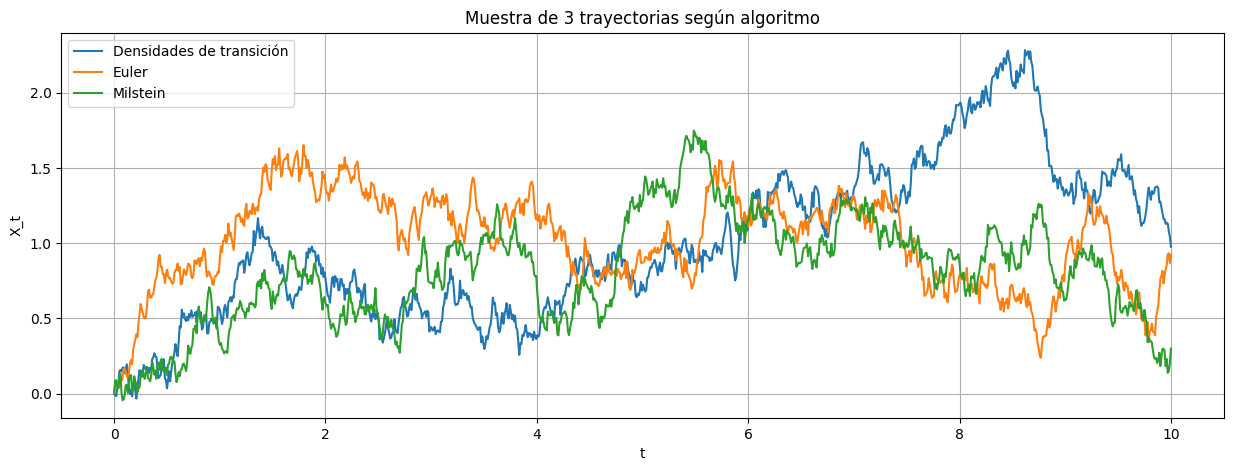

In [22]:
import matplotlib.pyplot as plt

T = 10
alpha = 1
lam = 1
sigma = 0.5
x0 = 0
delta = 1000

# Trayectorias
t, muestra_1 = OU_densidades(T, alpha, lam, sigma, x0, delta)
_, muestra_2 = OU_euler(T, alpha, lam, sigma, x0, delta)
_, muestra_3 = OU_milstein(T, alpha, lam, sigma, x0, delta)

# Grafica
plt.figure(figsize=(15, 5))
plt.plot(t, muestra_1, label="Densidades de transición")
plt.plot(t, muestra_2, label="Euler")
plt.plot(t, muestra_3, label="Milstein")

plt.title("Muestra de 3 trayectorias según algoritmo")
plt.xlabel("t")
plt.ylabel("X_t")
plt.grid()
plt.legend()
plt.show()

## Prueba de Kolmogorov-Smirnov

Para comparar las distribuciones obtenidas con los tres métodos utilizamos la prueba de Kolmogorov-Smirnov de dos muestras. Esta prueba contrasta las hipótesis

$$
H_0:\ F_1=F_2
$$

contra

$$
H_1:\ F_1\neq F_2,
$$

donde $F_1$ y $F_2$ son las funciones de distribución de las dos muestras que se comparan.

La estadística de Kolmogorov-Smirnov mide la máxima diferencia entre las funciones de distribución empíricas de ambas muestras. Si el $p$-value es mayor que el nivel de significancia $\alpha=0.05$, no se rechaza $H_0$; si es menor o igual que $0.05$, se rechaza $H_0$.

Se realizan las tres comparaciones: densidades de transición contra Euler, Euler contra Milstein y densidades de transición contra Milstein.

In [23]:
n = 1000
T = 1

muestra_1 = []
muestra_2 = []
muestra_3 = []

for _ in range(n):

    _, X1 = OU_densidades(T, alpha, lam, sigma, x0, delta)
    _, X2 = OU_euler(T, alpha, lam, sigma, x0, delta)
    _, X3 = OU_milstein(T, alpha, lam, sigma, x0, delta)

    muestra_1.append(X1[-1])
    muestra_2.append(X2[-1])
    muestra_3.append(X3[-1])

muestra_1 = np.array(muestra_1)
muestra_2 = np.array(muestra_2)
muestra_3 = np.array(muestra_3)

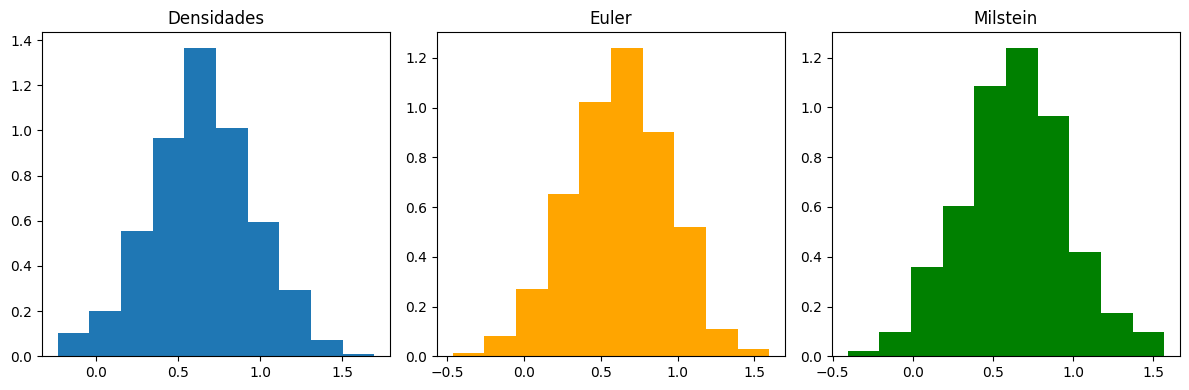

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].hist(muestra_1, density=True)
ax[0].set_title("Densidades")

ax[1].hist(muestra_2, density=True, color='orange')
ax[1].set_title("Euler")

ax[2].hist(muestra_3, density=True, color='green')
ax[2].set_title("Milstein")

plt.tight_layout()
plt.show()

In [26]:
from scipy import stats

comparaciones = [
    ("Densidades vs Euler", muestra_1, muestra_2),
    ("Euler vs Milstein", muestra_2, muestra_3),
    ("Densidades vs Milstein", muestra_1, muestra_3)
]

for nombre, x, y in comparaciones:

    ks = stats.ks_2samp(x, y)

    print(nombre)
    print("Estadística:", ks.statistic)
    print("P-value:", ks.pvalue)
    print()

Densidades vs Euler
Estadística: 0.047
P-value: 0.21939649929677082

Euler vs Milstein
Estadística: 0.029
P-value: 0.7946637387576738

Densidades vs Milstein
Estadística: 0.051
P-value: 0.14836452078962484



Los resultados muestran que no se rechaza $H_0$ para Densidades vs. Euler y Euler vs. Milstein, ya que sus $p$-values son mayores que $0.05$. En cambio, para Densidades vs. Milstein se obtiene $p=0.0484$, por lo que se rechaza $H_0$ al nivel de significancia del $5\%$.